In [86]:
import pandas as pd

# Define the path to your local CSV file
filepath = 'Clustering_dataset.csv'

# Load the dataset into a pandas DataFrame
df = pd.read_csv(filepath)

# --- Good practice after loading ---
# Inspect the first few rows
print("--- Data Head ---")
print(df.head())

# Check for missing values and data types
print("\n--- Data Info ---")
df.info()

--- Data Head ---
   CustomerID  Gender   Age  Annual_Income  Spending_Score
0           1    Male  19.0           15.0            39.0
1           2    Male  21.0            NaN            81.0
2           3  Female  20.0           16.0             6.0
3           4  Female  23.0           16.0            77.0
4           5  Female  31.0           17.0            40.0

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      200 non-null    int64  
 1   Gender          194 non-null    object 
 2   Age             194 non-null    float64
 3   Annual_Income   194 non-null    float64
 4   Spending_Score  194 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 7.9+ KB


In [87]:
# Before selecting columns, drop rows with any missing values
df.dropna(inplace=True)

# --- Good practice after loading ---
# Inspect the first few rows
print("--- Data Head ---")
print(df.head())

# Check for missing values and data types
print("\n--- Data Info ---")
df.info()

--- Data Head ---
   CustomerID  Gender   Age  Annual_Income  Spending_Score
0           1    Male  19.0           15.0            39.0
2           3  Female  20.0           16.0             6.0
3           4  Female  23.0           16.0            77.0
4           5  Female  31.0           17.0            40.0
5           6  Female  22.0           17.0            76.0

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 178 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      178 non-null    int64  
 1   Gender          178 non-null    object 
 2   Age             178 non-null    float64
 3   Annual_Income   178 non-null    float64
 4   Spending_Score  178 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 8.3+ KB


In [88]:
from sklearn.preprocessing import StandardScaler

# 2. Select the best numerical features for clustering
features = df[['Age', 'Annual_Income', 'Spending_Score']]

# 3. Scale the selected features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# The 'scaled_features' array is now ready for your K-Means algorithm
print("Data is scaled and ready for K-Means.")

Data is scaled and ready for K-Means.


In [89]:
import numpy as np

class MyKMeans:
    """
    A from-scratch implementation of the K-Means clustering algorithm.
    """
    def __init__(self, k, max_iters=100):
        self.k = k
        self.max_iters = max_iters
        self.centroids_ = None

    def _get_cluster_labels(self, X):
        """
        --- CORRECTED HELPER METHOD ---
        Helper function to assign each point to the nearest centroid.
        """
        # Reshape inputs to allow broadcasting. The subtraction results in an
        # array of shape (n_features, n_samples, k).
        diff = X[:, :, np.newaxis] - self.centroids_[:, np.newaxis, :]
        
        # Calculate the sum of squared differences along the feature axis (axis=0).
        # This results in a (n_samples, k) matrix where each entry is the
        # squared Euclidean distance from a sample to a centroid.
        distances_sq = np.sum(diff**2, axis=0)
        
        # Return the index (cluster) of the minimum distance for each sample.
        return np.argmin(distances_sq, axis=1)

    def fit(self, X):
        """
        Trains the K-Means model on the dataset X.
        
        Parameters:
        - X (np.array): Training data of shape (n_features, n_samples).
        """
        n_features, n_samples = X.shape
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids_ = X[:, random_indices]

        for _ in range(self.max_iters):
            old_centroids = self.centroids_.copy()
            
            labels = self._get_cluster_labels(X)
            
            # Update centroids by taking the mean of points in each cluster
            new_centroids = np.array([X[:, labels == i].mean(axis=1) for i in range(self.k)]).T
            self.centroids_ = new_centroids
            
            if np.all(old_centroids == self.centroids_):
                break
        return self

    def predict(self, X):
        """
        Assigns each data point in X to the nearest cluster.
        """
        if self.centroids_ is None:
            raise RuntimeError("The model has not been fitted yet. Please call fit() first.")
        
        return self._get_cluster_labels(X)

    def getCost(self, X):
        """
        Calculates the Within-Cluster Sum of Squares (WCSS).
        """
        cost = 0
        labels = self.predict(X)
        
        for i in range(self.k):
            cluster_points = X[:, labels == i]
            if cluster_points.shape[1] > 0:
                centroid = self.centroids_[:, i].reshape(-1, 1)
                cost += np.sum((cluster_points - centroid)**2)
                
        return cost

In [90]:
import pandas as pd
# Assume 'df' is your original DataFrame
# Assume 'scaled_features' is the NumPy array from StandardScaler
# Assume 'MyKMeans' class is defined in your script

# --- Step 1: Transpose the data for our custom class ---
# StandardScaler outputs (n_samples, n_features), our class needs (n_features, n_samples)
scaled_features_transposed = scaled_features.T


# --- Step 2: Instantiate and fit your K-Means model ---
k = 5  # A common starting point for this dataset
kmeans = MyKMeans(k=k, max_iters=150)
kmeans.fit(scaled_features_transposed)


# --- Step 3: Get the cluster assignments for each customer ---
labels = kmeans.predict(scaled_features_transposed)


# --- (Optional but Recommended) Step 4: Add the cluster labels back to your DataFrame ---
# First, ensure you are working with the cleaned DataFrame (no NaNs)
df_cleaned = df.dropna().copy()
df_cleaned['Cluster'] = labels


# Now you can analyze the results
print("--- First 5 Customers with their Assigned Cluster ---")
print(df_cleaned.head())

print("\n--- Number of Customers in Each Cluster ---")
print(df_cleaned['Cluster'].value_counts())

--- First 5 Customers with their Assigned Cluster ---
   CustomerID  Gender   Age  Annual_Income  Spending_Score  Cluster
0           1    Male  19.0           15.0            39.0        4
2           3  Female  20.0           16.0             6.0        0
3           4  Female  23.0           16.0            77.0        4
4           5  Female  31.0           17.0            40.0        4
5           6  Female  22.0           17.0            76.0        4

--- Number of Customers in Each Cluster ---
Cluster
4    49
2    38
3    37
1    34
0    20
Name: count, dtype: int64


In [91]:
import matplotlib.pyplot as plt

USERNAME = 'bhogadi.likhit'

def add_username_to_plot(username):
    """Helper method to add the username to a plot."""
    plt.text(
        0.95, 0.95, username,
        ha='right', va='top',
        transform=plt.gca().transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

In [92]:
import matplotlib.pyplot as plt
import numpy as np

# Assume 'MyKMeans' class is defined
# Assume 'scaled_features_transposed' is your data (3, n_samples)

wcss = []
k_range = range(1, 11)

print("Running Elbow Method...")
for k in k_range:
    # 1. Create and fit your custom MyKMeans
    kmeans = MyKMeans(k=k, max_iters=100)
    kmeans.fit(scaled_features_transposed)
    
    # 2. Get the cost using your getCost() method
    cost = kmeans.getCost(scaled_features_transposed)
    wcss.append(cost)
    
    print(f"  WCSS for k={k}: {cost:.2f}")

Running Elbow Method...
  WCSS for k=1: 534.00
  WCSS for k=2: 344.83
  WCSS for k=3: 267.58
  WCSS for k=4: 183.97
  WCSS for k=5: 160.88
  WCSS for k=6: 122.90
  WCSS for k=7: 109.11
  WCSS for k=8: 106.15
  WCSS for k=9: 98.08
  WCSS for k=10: 86.59


In [93]:
!pip install kneed

The optimal number of clusters (elbow) is: 4


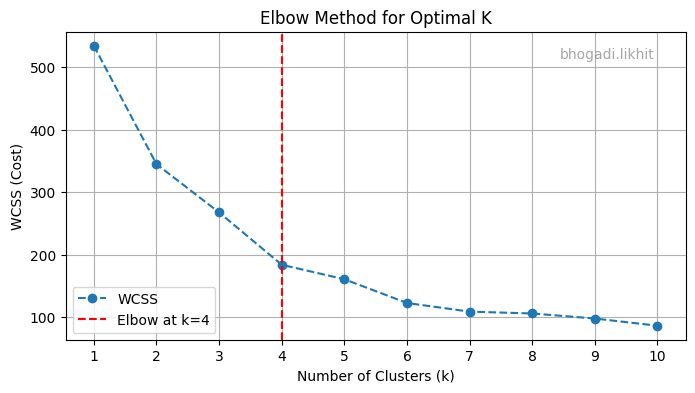

In [94]:
from kneed import KneeLocator
import matplotlib.pyplot as plt

# Assume 'k_range' and 'wcss' lists are already populated from the previous step

# 1. Use KneeLocator to find the elbow point
knee = KneeLocator(
    x=k_range, 
    y=wcss, 
    S=1.0,  # Sensitivity parameter, 1.0 is a good default
    curve='convex', 
    direction='decreasing'
)

optimal_k = knee.elbow
print(f"The optimal number of clusters (elbow) is: {optimal_k}")


# 2. Plot the WCSS values and the identified elbow
plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--', label='WCSS')

# Add a vertical line to mark the elbow
if optimal_k:
    plt.axvline(x=optimal_k, color='r', linestyle='--', label=f'Elbow at k={optimal_k}')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Cost)')
plt.xticks(k_range)
plt.legend()
plt.grid(True)
add_username_to_plot(USERNAME)
plt.show()


Running Silhouette Method...
  Silhouette Score for k=2: 0.3359
  Silhouette Score for k=3: 0.3413
  Silhouette Score for k=4: 0.3955
  Silhouette Score for k=5: 0.4110
  Silhouette Score for k=6: 0.3652
  Silhouette Score for k=7: 0.4084
  Silhouette Score for k=8: 0.3368
  Silhouette Score for k=9: 0.2956
  Silhouette Score for k=10: 0.3882


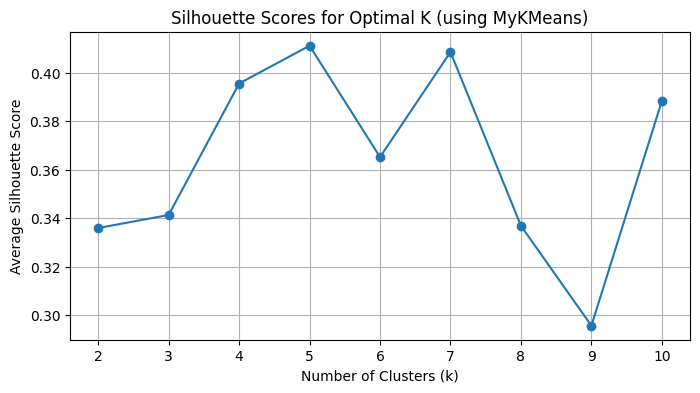

In [95]:
from sklearn.metrics import silhouette_score

# Assume 'scaled_features' is your (n_samples, 3) data
# Assume 'scaled_features_transposed' is your (3, n_samples) data

silhouette_scores = []
k_range_silhouette = range(2, 11) # Must start from k=2

print("\nRunning Silhouette Method...")
for k in k_range_silhouette:
    # 1. Create and fit your custom MyKMeans (uses transposed data)
    kmeans = MyKMeans(k=k, max_iters=100)
    kmeans.fit(scaled_features_transposed)
    
    # 2. Get the labels from your predict method
    labels = kmeans.predict(scaled_features_transposed)
    
    # 3. Calculate silhouette score (uses original scaled data)
    # We use 'scaled_features' here, not the transposed version.
    score = silhouette_score(scaled_features, labels)
    silhouette_scores.append(score)
    
    print(f"  Silhouette Score for k={k}: {score:.4f}")

# 4. Plot the Silhouette scores
plt.figure(figsize=(8, 4))
plt.plot(k_range_silhouette, silhouette_scores, marker='o', linestyle='-')
plt.title('Silhouette Scores for Optimal K (using MyKMeans)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.xticks(k_range_silhouette)
plt.grid(True)
plt.show()